## Module 2: FSHD Clinical Trial Project

Anna Brady <br>
Faye Chiang

## Project Goal:

Our project aims to determine whether MRI fat fraction or dorsiflexion strength more consistently capture change over time in the provided fascioscapulohumeral muscular dystrophy (FSHD) natural-history dataset. Because follow-up timing varies among participants, we will use linear models to estimate both measures at 12 and 24 months after baseline, applying interpolation or extrapolation as needed. We will compare matched measurements from the same participants and legs, evaluating the direction, standardized magnitude, and variability of estimated changes. We will also examine whether increases in fat fraction correspond to decreases in strength. These analyses will inform our recommendation of exploratory clinical-trial endpoints for monitoring FSHD progression, while acknowledging missing data, the assumption of linear change, and uncertainty in estimates beyond observed follow-up.

## Disease Background: 

* Prevalence & incidence
    - Facioscapulohumeral muscular dystrophy (FSHD) is an inherited muscular disorder. Prevalence describes how many people have a disease, whereas incidence describes the rate of new cases. A population-based study in the Netherlands estimated FSHD prevalence at 12 per 100,000 people, and incidence at 0.3 per 100,000 person-years. However, these estimates are derived from symptomatic individuals in that population and should not be treated as universal rates. The study also identified that underdiagnosis is an important consideration when estimating FSHD frequency. Deenen et al., 2014, Population-based incidence and prevalence of facioscapulohumeral dystrophy
* Symptoms
    - FSHD commonly causes asymmetric weakness of the facial muscles, shoulder-blade stabilizers, upper arms, and foot dorsiflexors. Symptoms can include difficulty closing the eyes, raising the arms, and lifting the front of the foot. Pain and fatigue may affect daily activities. Some individuals also experience respiratory weakness, hearing loss, or retinal abnormalities. Preston and Wang, GeneReviews: FSHD
* Diagnosis
    - Diagnosis combines the characteristic pattern of muscle weakness with genetic testing. FSHD1 testing evaluates contraction of the D4Z4 repeat array on chromosome 4 and whether it occurs on a disease-permissive genetic background. When FSHD2 is suspected, testing evaluates D4Z4 methylation and relevant genes involved in chromatin regulation, such as SMCHD1. Interpretation can be complex, so genetic findings must be considered alongside clinical features and family history. Giardina et al., 2024, Best practice guidelines on genetic diagnostics of facioscapulohumeral muscular dystrophy
* Standard of care treatments (& reimbursement) 
    - Care focuses on maintaining function and managing symptoms. Options include individualized physical therapy and exercise, ankle-foot orthoses for foot drop, pain management, and respiratory support. Selected patients may benefit from surgery to stabilize the shoulder blade. Monitoring also addresses hearing and eye complications when indicated. Preston and Wang, GeneReviews: FSHD
    - In the United States, reimbursement depends on insurance coverage and medical necessity. For example, Original Medicare Part B covers medically necessary outpatient physical therapy; after the deductible, patients generally pay 20% of the covered cost. Medically necessary prescribed arm and leg braces are also covered under Part B, subject to its requirements and cost sharing. These examples do not establish coverage for every person with FSHD. Medicare: Therapy Services, Medicare: Braces
* Disease progression & prognosis
    - FSHD usually progresses slowly, but severity varies among individuals. Weakness may eventually affect the lower limbs and mobility; approximately 20% of affected individuals require a wheelchair. Life expectancy is generally not shortened. This variable progression makes repeated measurements important when evaluating change over time. Preston and Wang, GeneReviews: FSHD
* Biological mechanisms (anatomy, organ physiology, cell & molecular physiology)
    - FSHD primarily affects skeletal muscle. Its central molecular feature is inappropriate expression of DUX4, a transcription factor that changes the activity of other genes. In FSHD1, contraction of the D4Z4 repeat array reduces repression of this region. In FSHD2, abnormalities in chromatin regulation similarly weaken repression. A permissive chromosome 4 background allows production of a stable DUX4 transcript. Genetic and Epigenetic Contributors to FSHD
    - Abnormal DUX4 activity disrupts muscle-cell gene regulation and is associated with oxidative stress, impaired muscle differentiation, and cell death. These processes help explain the loss of functional muscle tissue. For this project, the mechanism motivates examining complementary measurements: muscle composition through MRI fat fraction, force production through dorsiflexion strength, and physical performance through functional testing. DUX4 Signalling in the Pathogenesis of Facioscapulohumeral Muscular Dystrophy
* Clinical Trials/next-gen therapies
    - An important therapeutic strategy is to reduce DUX4 activity. Delpacibart braxlosiran is an investigational treatment designed to deliver small interfering RNA to muscle and reduce DUX4 expression. In June 2026, Novartis reported that the biomarker cohort of the Phase I/II FORTITUDE trial met its primary and key secondary biomarker endpoints; the company also reported that a Phase III study was enrolling. These sponsor-reported biomarker findings do not, by themselves, establish long-term functional benefit or regulatory approval. Novartis, June 11, 2026: FORTITUDE results
    - Another investigational treatment, losmapimod, was evaluated in the Phase III REACH trial. It did not significantly improve the primary reachable-workspace outcome compared with placebo, and Fulcrum announced suspension of further development in September 2024. The trial also assessed MRI muscle fat infiltration, strength, and patient-reported outcomes. Fulcrum Therapeutics, September 12, 2024: REACH results

## Data Set:

The provided clinical CSV contains data from 34 participants, with data collected at three different points: a baseline and two follow-up visits labeled T1 (year 1) and T2 (year 2). Not every participant has every measurement, and the actual time between T1 and T2 data collections varies significantly. The lag_months columns give how long after the intended sampling times the data was actually sampled. The data points are all natural-history observations, not results from an experimental treatment. Our project focuses on right- and left-leg MRI fat fraction and dorsiflexion quantitative muscle testing (QMT). Other columns include DUX4 gene-signature values, STIR measurements, timed movement tests, and clinical severity scores, among others.

The project identifies Wong et al. (2024) as the source study. That study used lower-extremity MRI, strength measurements, and TA muscle biopsies to study muscle changes and gene activity. MRI was used to measure fat infiltration, while biopsies were used for tissue and gene-expression analysis. [Wong et al., 2024](https://academic.oup.com/hmg/article/33/8/698/7588694)

The separate MRI teaching dataset contains eight cross-sections of subject UW_0020's left TA at each of two visits, TP1 and TP2. Each slice has a water-image file, a fat-image file, and a binary mask saved as NumPy .npy arrays. The images contain the half of the image with the TA, along with surrounding tissue. The supplied mask selects TA pixels with a value of 1 and excludes other pixels with a value of 0. We used the provided masks for our analysis rather than creating new segmentations or calculating whole-muscle volume. The masks were created by Springbok Analytics through a combination of an AI-based algorithm and manual vetting. [Supplied MRI README](FSHD_MRI_data/FSHD_MRI_data/FSHD_TA_MRI_data_0020_TP1_TP2/README.md)

The slice_info.csv file lists the filenames and locations. Samples are labeled from 10% to 80% along the muscle. Their distances range from 24 to 184 mm at TP1 and 24 to 196 mm at TP2, with unequal spacing. Water and fat arrays contain image signal intensities in the original acquisition units, not percentages. Our code calculates fat fraction as fat / (water + fat) * 100. The CSV fat-fraction values are percentages, and changes are expressed in percentage points. We keep QMT in the supplied units because the CSV does not state its physical unit. TP1 and TP2 in the image dataset are not assumed to be exactly 12 and 24 months. [Slice information](FSHD_MRI_data/FSHD_MRI_data/FSHD_TA_MRI_data_0020_TP1_TP2/slice_info.csv)


## MRI Data Analysis Methodology:

We used the supplied MRI example to calculate fat fraction in the left tibialis anterior (TA) for subject UW_0020. There are eight slices at each visit, TP1 and TP2. This part shows how the MRI measurements are calculated for one person. The CSV contains the measurements for the larger group used in our project.

The code is adapted from FSHD_TA_MRI_example_notebook.ipynb and Module2_interpolation_example.ipynb. We use linear interpolation for both 12 and 24 months to match our project goal.

First, we load the water images, fat images, and muscle masks with np.load. The slice_info.csv file tells us which files belong together and where each slice is along the muscle. Water and fat values are image signal intensities in the supplied acquisition units. The mask has a value of 1 inside the TA and 0 outside it.

Fat fraction is calculated as fat / (water + fat) * 100. We leave invalid pixels as NaN so they do not count as zero. We calculate values for the whole supplied image region and then apply the mask to keep only the TA. The whole region includes other tissue and background, so its mean is not the muscle's fat fraction.

In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.interpolate import interp1d
from IPython.display import display

DATA_DIR = Path("FSHD_MRI_data/FSHD_MRI_data/FSHD_TA_MRI_data_0020_TP1_TP2")
manifest = pd.read_csv(DATA_DIR / "slice_info.csv")

row = manifest[manifest["timepoint"] == "TP1"].iloc[3]
water = np.load(DATA_DIR / row["water_file"])
fat = np.load(DATA_DIR / row["fat_file"])
mask = np.load(DATA_DIR / row["mask_file"]).astype(bool)

print("Water image shape:", water.shape)
print("Fat image shape:", fat.shape)
print("Mask shape:", mask.shape)
print("Number of muscle pixels:", mask.sum())

def calculate_fat_fraction(water, fat, mask=None):
    water = water.astype(float)
    fat = fat.astype(float)
    denominator = water + fat
    valid_pixels = (np.isfinite(water) & np.isfinite(fat)
                    & (water >= 0) & (fat >= 0) & (denominator > 0))
    result = np.divide(fat, denominator,
                       out=np.full_like(fat, np.nan), where=valid_pixels) * 100
    if mask is not None:
        result[~mask] = np.nan
    return result

fat_fraction_full = calculate_fat_fraction(water, fat)
fat_fraction_masked = calculate_fat_fraction(water, fat, mask)
whole_image_values = fat_fraction_full[np.isfinite(fat_fraction_full)]
muscle_values = fat_fraction_masked[np.isfinite(fat_fraction_masked)]

print("Whole region mean (%):", np.mean(whole_image_values))
print("TA mean (%):", np.mean(muscle_values))
print("TA median (%):", np.median(muscle_values))
print("TA standard deviation (%):", np.std(muscle_values))

Water image shape: (266, 224)
Fat image shape: (266, 224)
Mask shape: (266, 224)
Number of muscle pixels: 360
Whole region mean (%): 48.58431054863835
TA mean (%): 29.93173268255653
TA median (%): 25.369645575125027
TA standard deviation (%): 21.584494891676016


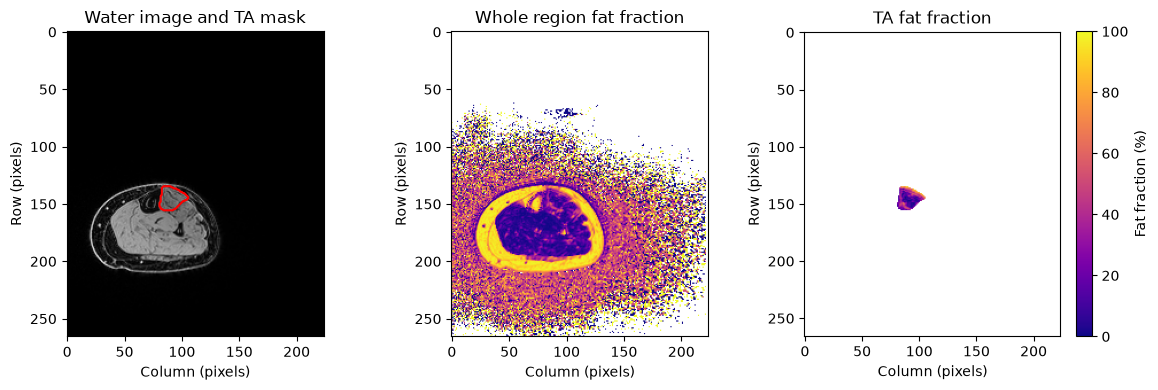

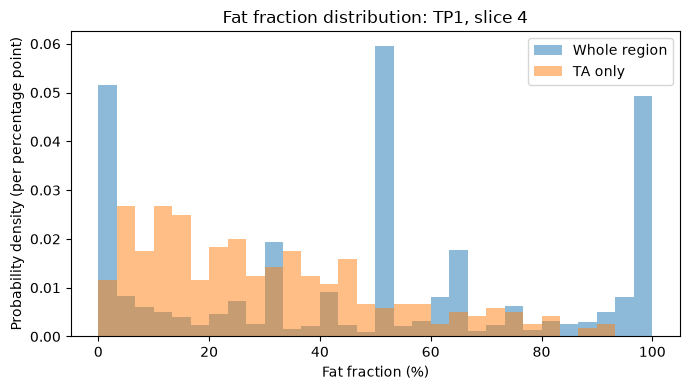

In [ ]:
# Graphing MRI data and fat fraction distribution
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
axes[0].imshow(water, cmap="gray")
axes[0].contour(mask, levels=[0.5], colors="red")
axes[0].set_title("Water image and TA mask")
image1 = axes[1].imshow(fat_fraction_full, cmap="plasma", vmin=0, vmax=100)
axes[1].set_title("Whole region fat fraction")
image2 = axes[2].imshow(fat_fraction_masked, cmap="plasma", vmin=0, vmax=100)
axes[2].set_title("TA fat fraction")
for ax in axes:
    ax.set_xlabel("Column (pixels)")
    ax.set_ylabel("Row (pixels)")
fig.colorbar(image2, ax=axes[2], label="Fat fraction (%)")
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 4))
plt.hist(whole_image_values, bins=np.linspace(0, 100, 31), density=True,
         alpha=0.5, label="Whole region")
plt.hist(muscle_values, bins=np.linspace(0, 100, 31), density=True,
         alpha=0.5, label="TA only")
plt.xlabel("Fat fraction (%)")
plt.ylabel("Probability density (per percentage point)")
plt.title("Fat fraction distribution: TP1, slice 4")
plt.legend()
plt.tight_layout()
plt.show()

Figures 1 and 2 show one slice from TP1. The mask separates the TA from surrounding tissue. The histograms show why the whole-region measurement differs from the TA measurement. Density is used because the two regions contain different numbers of pixels.

Next, we repeat the calculation for all slices. We calculate the mean, median, and standard deviation of the valid TA pixels, as well as the number of mask pixels and valid pixels. Standard deviation describes the spread of pixel values, not the uncertainty in the mean. We also keep the whole-region mean for comparison.

,timepoint,slice_id,distance_mm,percent_along_muscle,mean_ff,median_ff,std_ff,n_muscle_pixels,n_valid_pixels,whole_region_mean_ff
0,TP1,1,24.0,10,83.92,88.83,13.27,61,61,50.29
1,TP1,2,44.0,20,82.71,86.65,12.43,115,115,50.15
2,TP1,3,68.0,30,58.50,61.82,22.88,231,231,49.41
3,TP1,4,92.0,40,29.93,25.37,21.58,360,360,48.58
4,TP1,5,116.0,50,20.87,14.55,20.06,421,421,48.47
5,TP1,6,136.0,60,16.76,9.05,19.67,440,440,48.71
6,TP1,7,160.0,70,17.51,8.96,20.46,388,388,49.15
7,TP1,8,184.0,80,27.87,22.69,22.63,263,263,50.00
8,TP2,1,24.0,10,82.39,90.84,15.91,46,46,51.01
9,TP2,2,48.0,20,84.05,92.03,17.74,74,74,50.63


,mean,std
timepoint,,
TP1,42.26,28.57
TP2,54.41,25.08


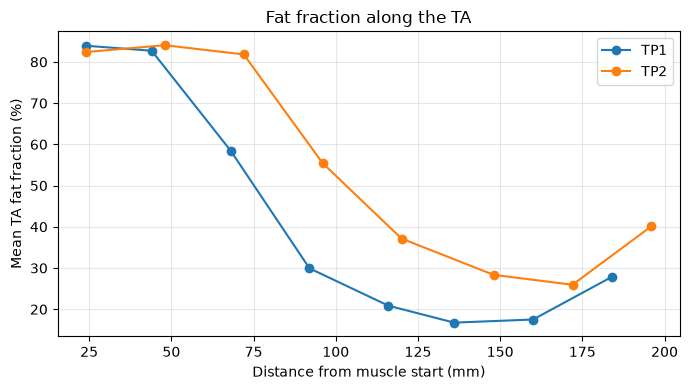

In [3]:
results = []
for _, row in manifest.iterrows():
    water = np.load(DATA_DIR / row["water_file"])
    fat = np.load(DATA_DIR / row["fat_file"])
    mask = np.load(DATA_DIR / row["mask_file"]).astype(bool)
    ff = calculate_fat_fraction(water, fat, mask)
    ff_full = calculate_fat_fraction(water, fat)
    results.append({
        "timepoint": row["timepoint"],
        "slice_id": row["slice_id"],
        "distance_mm": row["distance_from_muscle_start_mm"],
        "percent_along_muscle": row["percent_along_muscle"],
        "mean_ff": np.nanmean(ff),
        "median_ff": np.nanmedian(ff),
        "std_ff": np.nanstd(ff),
        "n_muscle_pixels": int(mask.sum()),
        "n_valid_pixels": int(np.isfinite(ff).sum()),
        "whole_region_mean_ff": np.nanmean(ff_full)
    })

results_df = pd.DataFrame(results)
display(results_df.round(2))
display(results_df.groupby("timepoint")["mean_ff"].agg(["mean", "std"]).round(2))

plt.figure(figsize=(7, 4))
for timepoint, group in results_df.groupby("timepoint"):
    group = group.sort_values("distance_mm")
    plt.plot(group["distance_mm"], group["mean_ff"], marker="o", label=timepoint)
plt.xlabel("Distance from muscle start (mm)")
plt.ylabel("Mean TA fat fraction (%)")
plt.title("Fat fraction along the TA")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Figure 3 shows how mean fat fraction varies along the muscle at both visits. Each point is a measured slice summary. The visit table gives the average and sample standard deviation of the eight slice means. This gives equal weight to each slice and is not a whole-muscle volume average. Slice spacing is unequal, so we use the actual distance in millimeters. TP1 and TP2 do not always have the same distances, so directly subtracting values by slice number would not compare identical positions.

For the project comparison, we use the clinical CSV and actual visit times in months. The MRI image visit labels do not provide elapsed months, so we do not assign them dates or use them to fill missing values in the clinical CSV.

The following code follows the class interpolation example for subject 13-0004, using right-leg fat fraction and right-leg dorsiflexion strength. We use 12 and 24 months instead of the class example's earliest visit times. We remove missing time/value pairs separately for each measure. At least two distinct times are needed.

Linear interpolation uses the line between the two measurements around the target time. Outside the observed times, we extend the nearest end segment and call it extrapolation. This is piecewise linear interpolation, not one regression line fitted to all visits. We assume each visit's lag_months value applies to both measurements because separate dates are not provided.

Fat fraction at 12 months, matrix method: 10.906213205081567


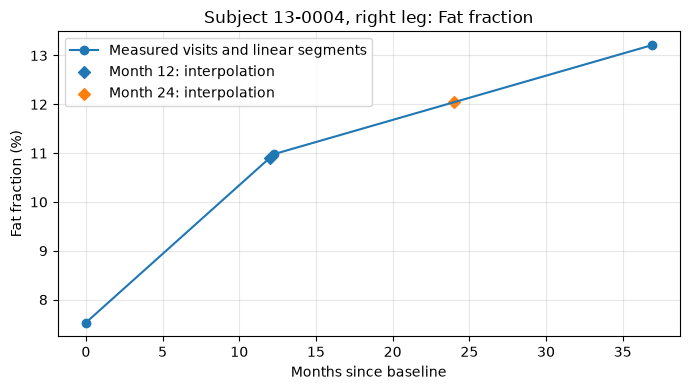

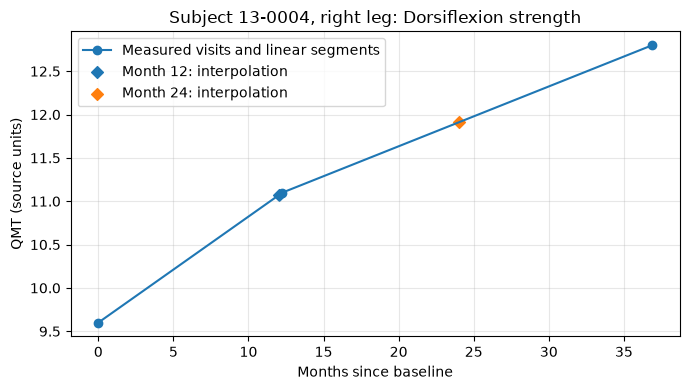

,measure,month,estimate,type,months_outside_data,plausible
0,Fat fraction,12,10.906,interpolation,0,True
1,Fat fraction,24,12.043,interpolation,0,True
2,Dorsiflexion strength,12,11.068,interpolation,0,True
3,Dorsiflexion strength,24,11.910,interpolation,0,True


In [4]:
df = pd.read_csv("Module2_FSHD_Dataset.csv")
row = df.loc[df["subject_id"] == "13-0004"].iloc[0]

lag_months = np.array([row["lag_months_baseline"], row["lag_months_y1"], row["lag_months_y2"]])
ff_values = np.array([row["ff_baseline_R"], row["ff_y1_R"], row["ff_y2_R"]])
strength_values = np.array([row["dorsiflexion_qmt_R_baseline"],
                            row["dorsiflexion_qmt_R_y1"],
                            row["dorsiflexion_qmt_R_y2"]])
T1 = 12
T2 = 24

# The matrix method from the example, using the two points around month 12.
valid = np.isfinite(lag_months) & np.isfinite(ff_values)
x = lag_months[valid]
y = ff_values[valid]
order = np.argsort(x)
x, y = x[order], y[order]
i = int(np.clip(np.searchsorted(x, T1) - 1, 0, len(x) - 2))
x1, x2 = x[i], x[i + 1]
y1, y2 = y[i], y[i + 1]
Z = np.array([[1, x1], [1, x2]])
Y = np.array([y1, y2])
A = np.linalg.solve(Z, Y)
a1, a2 = A
estimate_T1 = a1 + a2 * T1
print("Fat fraction at 12 months, matrix method:", estimate_T1)

# The same approach with interp1d, for both measurements.
estimates = []
for name, values, units in [("Fat fraction", ff_values, "Fat fraction (%)"),
                            ("Dorsiflexion strength", strength_values, "QMT (source units)")]:
    valid = np.isfinite(lag_months) & np.isfinite(values)
    x = lag_months[valid]
    y = values[valid]
    order = np.argsort(x)
    x, y = x[order], y[order]
    if len(x) < 2 or len(np.unique(x)) != len(x):
        for target in [T1, T2]:
            estimates.append({"measure": name, "month": target,
                              "estimate": np.nan, "type": "not enough distinct times"})
        continue

    f_linear = interp1d(x, y, kind="linear", bounds_error=False, fill_value="extrapolate")
    if name == "Fat fraction":
        assert np.isclose(f_linear(T1), estimate_T1)
    plt.figure(figsize=(7, 4))
    plt.plot(x, y, "o-", label="Measured visits and linear segments")
    for target in [T1, T2]:
        estimate = float(f_linear(target))
        outside = max(x[0] - target, target - x[-1], 0)
        estimate_type = "extrapolation" if outside > 0 else "interpolation"
        if np.isclose(x, target).any():
            estimate_type = "observed"
        plausible = 0 <= estimate <= 100 if name == "Fat fraction" else estimate >= 0
        estimates.append({"measure": name, "month": target, "estimate": estimate,
                          "type": estimate_type, "months_outside_data": outside,
                          "plausible": plausible})
        plt.scatter(target, estimate, marker="D", label=f"Month {target}: {estimate_type}")
        if outside > 0:
            end = 0 if target < x[0] else -1
            plt.plot([x[end], target], [y[end], estimate], "--", color="gray")
    plt.xlabel("Months since baseline")
    plt.ylabel(units)
    plt.title("Subject 13-0004, right leg: " + name)
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

estimates_df = pd.DataFrame(estimates)
display(estimates_df.round(3))

Figures 4 and 5 show the observed values and the estimates at 12 and 24 months for one participant. Both measures increase in this example, so increasing fat fraction does not necessarily correlate with decreasing strength for every person. This example shows the method, not a result for the whole group. Strength is labeled in source units because the CSV does not state the physical units.

For the full analysis, we will repeat this process for each participant and leg. We will compare only matching participants and legs with baseline values and enough data for both measures. Right and left legs will be analyzed separately so they are not counted as independent participants. Missing estimates will remain NaN. We will flag impossible predictions rather than change them, report exclusions, and compare results with and without extrapolated values.

We will calculate fat-fraction change as follow-up minus baseline, and strength decline as baseline minus follow-up. Positive values then mean worsening for both measures. We will compare the proportion showing worsening, the mean change, and the standard deviation of change. Since the units differ, we will also divide changes by each measure's baseline standard deviation in the same matched group. This calculation is only possible if that standard deviation is not zero. A scatterplot of fat-fraction change against strength decline will show whether the changes are related.

The main assumptions are that changes are linear between visits and that the same trend continues when extrapolating. Estimated values are not new measurements. Missing visits, mask accuracy, measurement variability, and longer extrapolation distances can affect the results. This methods example cannot tell us which measure is better across the full group or whether either measure detects a treatment effect.

## Interpolation Analysis:

Because sampling times for the subjects did not consistently line up at the 12- and 24-month marks, interpolation was used with the data from the delayed testings to fill in the missing data points, in order to be more consistent with analyses of trends and draw more accurate conclusions. The locations of the interpolations were at the 12- and 24- month marks, or T1 and T2, and were defined in months since baseline.

The linear interpolation was conducted using Python's interp1d function:
```python
from scipy.interpolate import interp1d
```

The following code was used to interpolate dorsiflexion strength and fat fraction in the right leg of patient 13-0004, and generate graphs with the interpolated and measured data:
```python
df = pd.read_csv("Module2_FSHD_Dataset.csv")
row = df.loc[df["subject_id"] == "13-0004"].iloc[0] # Extracts data for specific patient

# Extracts time in months between intended and actual sampling points:
lag_months = np.array([row["lag_months_baseline"], row["lag_months_y1"], row["lag_months_y2"]]) 
# Extracts fat fraction values:
ff_values = np.array([row["ff_baseline_R"], row["ff_y1_R"], row["ff_y2_R"]])
# Extracts dorsiflexion data values:
strength_values = np.array([row["dorsiflexion_qmt_R_baseline"], row["dorsiflexion_qmt_R_y1"], row["dorsiflexion_qmt_R_y2"]])

# Set T1 and T2 to number of months:
T1 = 12
T2 = 24

estimates = []
for name, values, units in [("Fat fraction", ff_values, "Fat fraction (%)"), ("Dorsiflexion strength", strength_values, "QMT (source units)")]:
    valid = np.isfinite(lag_months) & np.isfinite(values)
    x = lag_months[valid]
    y = values[valid]
    order = np.argsort(x)
    x, y = x[order], y[order]
    if len(x) < 2 or len(np.unique(x)) != len(x):
        for target in [T1, T2]:
            estimates.append({"measure": name, "month": target,
                              "estimate": np.nan, "type": "not enough distinct times"})
        continue
    
    # Run the interp1d function to interpolate the missing data points
    f_linear = interp1d(x, y, kind="linear", bounds_error=False, fill_value="extrapolate")
    if name == "Fat fraction":
        assert np.isclose(f_linear(T1), estimate_T1)

    # Plot interpolated and actual data for fat fraction and dorsiflexion
    plt.figure(figsize=(7, 4))
    plt.plot(x, y, "o-", label="Measured visits and linear segments")
    for target in [T1, T2]:
        estimate = float(f_linear(target))
        outside = max(x[0] - target, target - x[-1], 0)
        estimate_type = "extrapolation" if outside > 0 else "interpolation"
        if np.isclose(x, target).any():
            estimate_type = "observed"
        plausible = 0 <= estimate <= 100 if name == "Fat fraction" else estimate >= 0
        estimates.append({"measure": name, "month": target, "estimate": estimate,
                          "type": estimate_type, "months_outside_data": outside,
                          "plausible": plausible})
        plt.scatter(target, estimate, marker="D", label=f"Month {target}: {estimate_type}")
        if outside > 0:
            end = 0 if target < x[0] else -1
            plt.plot([x[end], target], [y[end], estimate], "--", color="gray")
    plt.xlabel("Months since baseline")
    plt.ylabel(units)
    plt.title("Subject 13-0004, right leg: " + name)
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

estimates_df = pd.DataFrame(estimates) # Create a data frame with estimated data points
display(estimates_df.round(3))
```

The code generated the following graphs.

Interpolated and measured dorsiflexion data for patient 13-0004:

![alt text](<Screenshot 2026-10-22 201356.png>)

Interpolated and measured fat fraction data for patient 13-0004:

![alt text](<Screenshot 2026-10-22 201735.png>)

The interpolated data is an estimate, rather than a new measurement, because the function uses available data to make it's best guess at where a new point would fall. The analysis assumes that the interpolated quantities, in this case fat fraction and dorsiflexion, change linearly between measured locations, as opposed to quadratically. The estimate is within the sampled data and thus is an interpolation, and not an extrapolation. However, as the interpolation is only an estimate, the actual values may be different especially if they do not align with the linear model used in the interpolation function.

## Conclusions:

In our MRI example, fat fraction varied along the TA muscle and between visits. The average of the eight slice means increased from 42.26% at TP1 to 54.41% at TP2. This suggests that the location we measure matters. However, the slices were not taken at exactly the same positions at both visits, so this difference may partly be due to sampling. Using the muscle mask also helped keep surrounding tissue out of the TA measurement.

For the separate participant used in our interpolation example, both fat fraction and dorsiflexion strength increased between the estimated 12- and 24-month values. This shows that an increase in fat fraction did not go along with a decrease in strength in this case. We cannot say which measure changed more consistently or was more sensitive overall because we have not yet compared all participants. The examples show differences, but they do not fully answer our project question.

Both measures could be useful as exploratory endpoints in clinical trials. MRI fat fraction describes muscle composition, while dorsiflexion strength measures how much force a person can produce. For now, we would keep both measures for further analysis. Before using them to judge whether a treatment works, we would need more participants and visits, to check that the results are replicable, and a treatment study with a comparison group. We would also need to see whether the changes matter to patients. Interpolation and extrapolation give estimates, and assuming linear change may not always be accurate.

Choosing an endpoint also affects patients. Using only MRI could miss meaningful changes in strength or daily activities. We should consider whether patients can access the testing and whether cost, travel, or the amount of testing makes participation difficult. Using both measures may give a fuller picture, but the benefit of extra information should be balanced with the burden on patients.

Comparison with published studies:

Wong et al. (2024) found that fat infiltration varied along the TA and that regional and whole-muscle measurements could differ. Our example also showed large differences between slices, which supports the importance of sampling location. However, our eight-slice average is not the same measurement as their whole-muscle fat percentage. Because the teaching data are related to the source study, this is a consistency check rather than independent validation. [Wong et al., 2024](https://academic.oup.com/hmg/article/33/8/698/7588694)

A 2021 longitudinal study reported that TA fat fraction and strength had a curved relationship, with a sharper strength decrease above about 20% fat replacement. Our example participant's estimated fat fraction was about 11–12%, and strength increased rather than decreased. This does not show the same strength-loss pattern, but a change within one person at low fat fraction is not directly comparable to a relationship across many muscles. Different sampling methods and measurement variability could also affect the comparison. The study supports examining both measures, but it does not prove that our estimates are accurate. [Longitudinal study of MRI and functional outcome measures in FSHD, 2021](https://pubmed.ncbi.nlm.nih.gov/33691664/)

Our code also checks that the matrix calculation and interp1d give the same 12-month fat-fraction estimate. This checks the calculation, but not whether linear change is a good description of the disease. More observations would be needed to test that assumption.


## Limitations and Future Work:

Our clinical dataset has only 34 participants, which limits the precision of the results and how well they can be applied to other people with FSHD. There are at most three visits per participant, and some measurements are missing. The visits also occurred at different times, with inconsistent time in between. Comparing only people with complete measurements could leave out participants with different disease patterns.

The MRI example includes only one person's left TA and eight slices per visit. These slices do not cover every location, and the physical positions differ between visits. Mistakes in the muscle mask could include surrounding tissue or exclude muscle pixels. Image noise can also affect fat-fraction values. Averaging the slice means is not the same as measuring fat fraction throughout the whole muscle.

Dorsiflexion strength may vary with effort, positioning, and testing technique, so a change may not be due only to disease progression. We have not analyzed the other biomarkers or functional tests, so we cannot say how our two selected measures compare with all available endpoints. Our current worked examples also do not establish a result for the full group.

Linear interpolation assumes a straight-line change between visits. Extrapolation assumes that the same trend continues beyond the observed data, which becomes more uncertain farther from a visit. A value within the allowed range is not necessarily accurate. Estimated values should not be treated as extra independent measurements.

With more time, we would complete the matched-participant analysis and compare results with and without extrapolation. We would include more participants, more regularly timed visits, and repeat strength measurements. We would also compare additional muscles and daily-function tests. A treatment study with an appropriate comparison group would be needed to test whether these measures detect treatment effects.


## AI Usage Statement:

We used ChatGPT (OpenAI, October 2026) to help find sources and research the FSHD disease background. It also helped draft the background information and found sources for us to reference. For the code, ChatGPT helped adapt the class examples to compare MRI fat fraction and dorsiflexion strength at 12 and 24 months.


## GitHub Repository Link:
[bme2315_module2_fshd]:https://github.com/amccollbrady/bme2315_module2_fshd

https://github.com/amccollbrady/bme2315_module2_fshd


## References:
**References**

1. Deenen et al. (2014). *Population-based incidence and prevalence of facioscapulohumeral dystrophy.*  
   [PubMed](https://pubmed.ncbi.nlm.nih.gov/25122204/)

2. Preston, M. K., & Wang, L. H. (2025). *Facioscapulohumeral muscular dystrophy.* GeneReviews.  
   [NCBI Bookshelf](https://www.ncbi.nlm.nih.gov/books/NBK1443/)

3. Giardina et al. (2024). *Best practice guidelines on genetic diagnostics of facioscapulohumeral muscular dystrophy: Update of the 2012 guidelines.*  
   [PubMed](https://pubmed.ncbi.nlm.nih.gov/38685133/)

4. Medicare. *Medicare coverage of therapy services.*  
   [Medicare fact sheet](https://www.medicare.gov/publications/10988-medicare-coverage-of-therapy-services.pdf)

5. Medicare. *Braces (arm, leg, back, & neck).*  
   [Medicare coverage information](https://www.medicare.gov/coverage/braces-arm-leg-back-neck)

6. *Genetic and epigenetic contributors to FSHD.* (2015).  
   [PubMed Central](https://pmc.ncbi.nlm.nih.gov/articles/PMC4674299/)

7. *DUX4 signalling in the pathogenesis of facioscapulohumeral muscular dystrophy.* (2020).  
   [PubMed Central](https://pmc.ncbi.nlm.nih.gov/articles/PMC7037115/)

8. Novartis. (2026, June 11). *Novartis delpacibart braxlosiran (del-brax) Phase I/II study in facioscapulohumeral muscular dystrophy (FSHD) meets primary biomarker endpoint.* [Press release].  
   [Novartis](https://www.novartis.com/news/media-releases/novartis-delpacibart-braxlosiran-del-brax-phase-iii-study-facioscapulohumeral-muscular-dystrophy-fshd-meets-primary-biomarker-endpoint)

9. Fulcrum Therapeutics. (2024, September 12). *Fulcrum Therapeutics announces topline results from Phase 3 REACH clinical trial of losmapimod in facioscapulohumeral muscular dystrophy (FSHD).* [Press release].  
   [Fulcrum Therapeutics](https://ir.fulcrumtx.com/news-releases/news-release-details/fulcrum-therapeutics-announces-topline-results-phase-3-reach)

10. Wong et al. (2024). *Regional and bilateral MRI and gene signatures in facioscapulohumeral dystrophy: implications for clinical trial design and mechanisms of disease progression*<br>
   [Oxford Academic](https://academic.oup.com/hmg/article/33/8/698/7588694?login=false)

11. *Longitudinal study of MRI and functional outcome measures in facioscapulohumeral muscular dystrophy.* (2021). BMC Musculoskeletal Disorders. [PubMed](https://pubmed.ncbi.nlm.nih.gov/33691664/)

12. Supplied course materials: *Student MRI sample: tibialis anterior at two visits* and *slice_info.csv*. [Dataset README](FSHD_MRI_data/FSHD_MRI_data/FSHD_TA_MRI_data_0020_TP1_TP2/README.md), [Slice information](FSHD_MRI_data/FSHD_MRI_data/FSHD_TA_MRI_data_0020_TP1_TP2/slice_info.csv)
